# Week 7 - Clipping

In this lesson we will learn how to clip different geometries.

By the end of this lesson, you will be able to:

- reproject geo-dataframes so they share the same CRS 
- clip a `geopandas.GeoDataFrame` to the polygons of another one using `geopandas.clip()`
- subset tabular data before applying geospatial operations
- decide when to clip to a bounding box instead of the exact polygons

## About the data

We will use three datasets. Put each unzipped folder inside a `data/` folder at the same level as this notebook.

1. **US states**: the 2026 [TIGER shapefile of the US states](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html#form-dropdown-790442341) from the United States Census Bureau. You already have this dataset in your computer. 

2. **Populated places**: [Natural Earth's medium-scale populated places dataset (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). Under "Populated Places", download the simple version (the one that says "simple (less columns)"). You will get a `ne_50m_populated_places_simple` folder.

3. **Roads**: [Natural Earth's large-scale roads dataset (1:10m)](https://www.naturalearthdata.com/downloads/10m-cultural-vectors/roads/). Download the shapefile. You will get a `ne_10m_roads` folder.

Read the [lesson's "About the data" section](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-13-clipping/lesson-13-clipping.html#about-the-data) for more information about the datasets, including the column descriptions of the US states shapefile.

## Import data

Let's start by loading our libraries and then importing the datasets we will use.

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import box  # To create polygon bounding box


pd.set_option("display.max.columns", None)

# -------------------------------------------------------
# === MODIFY AS NEEDED TO IMPORT YOUR DATA ===

# Import states polygons
states = gpd.read_file(os.path.join('data', 
                                    'tl_2026_us_state1', 
                                    'tl_2026_us_state.shp'))

# Import Natural Earth populated places points
places = gpd.read_file(os.path.join('data',
                                    'ne_50m_populated_places_simple',
                                    'ne_50m_populated_places_simple.shp')
                                    )

# Import roads lines
roads = gpd.read_file(os.path.join('data',
                                   'ne_10m_roads1',
                                   'ne_10m_roads.shp')
                                   )

## Check-in (complete before class)
Use a `for` loop to iterate over the three geo-dataframes we imported and change their column names to lowercase.

In [20]:
df_lower = [states, places, roads]

for df in df_lower:
    df.columns = df.columns.str.lower()

In [21]:
states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

## Prepare Alsaka multipolygon 

In [22]:
print('CRS: ', states.crs)
print(len(states))
states.head()

CRS:  EPSG:4269
56


,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."
3,9,0,60,01802701,60,0400000US60,AS,American Samoa,00,G4000,A,197759077,1307243766,-14.2668475,-170.6671854,"MULTIPOLYGON (((-168.22527 -14.53591, -168.224..."
4,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872617229,1030604623,+44.0589536,-072.6710173,"POLYGON ((-72.04187 44.15665, -72.04180 44.156..."


<Axes: >

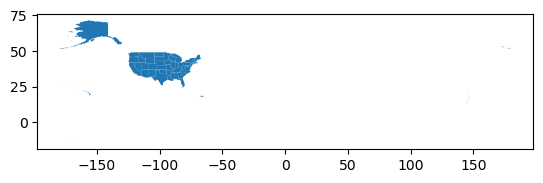

In [23]:
states.plot()

<Axes: >

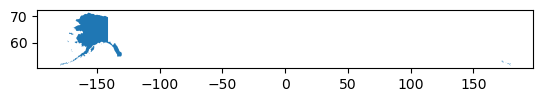

In [24]:
alaska = states[states['name']== "Alaska"]
alaska.plot()

In [25]:
# Reproject to CRS optimized for Alaska 
# Each CRS uses diffrent numbers to map points
alaska = alaska.to_crs('epsg:3338')

# Inspect CRS
alaska.crs

# With projected CRS it is linear 
# Axis infor provides information on how map is measured (ex: Meters)

<Projected CRS: EPSG:3338>
Name: NAD83 / Alaska Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - Alaska.
- bounds: (172.42, 51.3, -129.99, 71.4)
Coordinate Operation:
- name: Alaska Albers (meter)
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

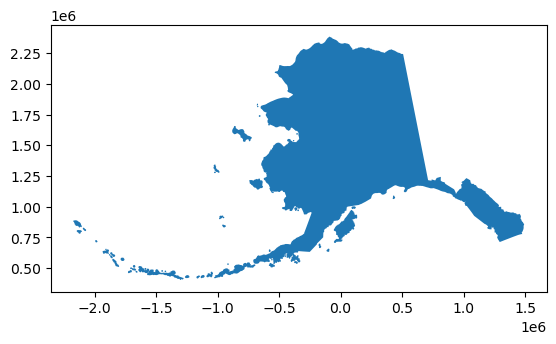

In [26]:
alaska.plot()

## Prepare populated places points

In [27]:
print("CRS:", places.crs)
print(len(places))
places.head()

CRS: EPSG:4326
1251


,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,capin,worldcity,megacity,sov0name,sov_a3,adm0name,adm0_a3,adm1name,iso_a2,note,latitude,longitude,pop_max,pop_min,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry
0,10,1,5,Admin-1 region capital,Bombo,None,None,Bombo,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Bamunanika,UG,None,0.583299,32.533300,75000,21000,0.0,8,7,None,None,7.0,1159113923,POINT (32.53330 0.58330)
1,10,1,5,Admin-1 region capital,Fort Portal,None,None,Fort Portal,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Kabarole,UG,None,0.671004,30.275002,42670,42670,0.0,7,7,None,None,7.0,1159113959,POINT (30.27500 0.67100)
2,10,1,3,Admin-1 region capital,Potenza,None,None,Potenza,0,0,None,0,0,Italy,ITA,Italy,ITA,Basilicata,IT,None,40.642002,15.798997,69060,69060,0.0,8,8,None,None,7.0,1159117259,POINT (15.79900 40.64200)
3,10,1,3,Admin-1 region capital,Campobasso,None,None,Campobasso,0,0,None,0,0,Italy,ITA,Italy,ITA,Molise,IT,None,41.562999,14.655997,50762,50762,0.0,8,8,None,None,7.0,1159117283,POINT (14.65600 41.56300)
4,10,1,3,Admin-1 region capital,Aosta,None,None,Aosta,0,0,None,0,0,Italy,ITA,Italy,ITA,Valle d'Aosta,IT,None,45.737001,7.315003,34062,34062,0.0,7,7,None,None,7.0,1159117361,POINT (7.31500 45.73700)


<Axes: >

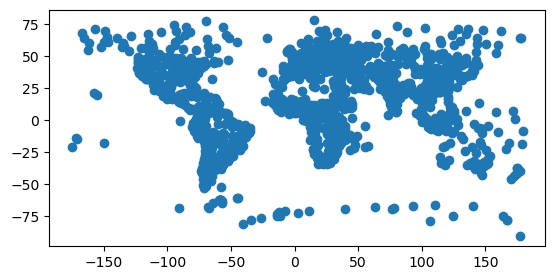

In [28]:
places.plot()

<Axes: >

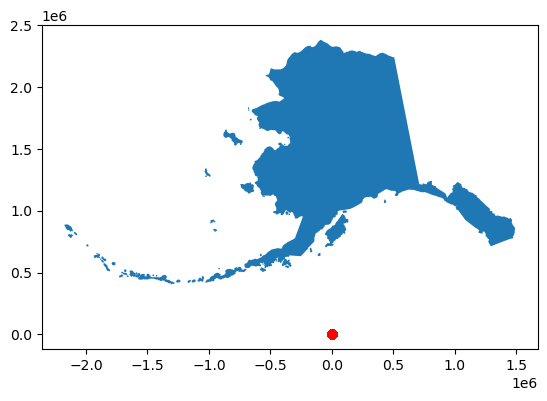

In [29]:
fig, ax=plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red')

# CRS do not match

In [30]:
# Reproject to match ALska CRS

places = places.to_crs(alaska.crs)

assert alaska.crs==places.crs

<Axes: >

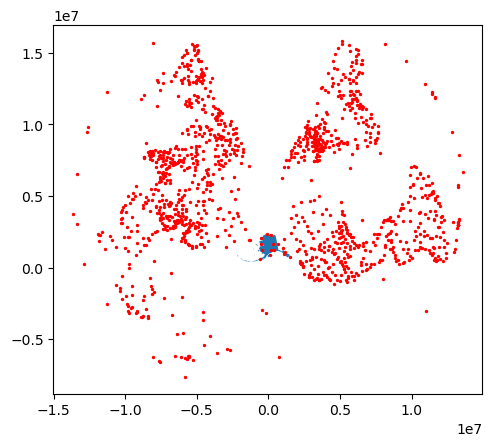

In [31]:
fig, ax=plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red', markersize=2)

# Points not in our designated areas will be distorted 

##clipping

**clipping** means using a polygon (or polygons) to keep only the part of the geometries that fall inside them.
```python
updated_geodf = geopandas.clip(geodf, mask)
```

where: 
- `updated_geodf` is the output of the function: the intersection of the geometries in geodf with mask,
- `geodf` is the geopandas.GeoDataFrame we want to clip,
- `mask` is a geopandas.GeoDataFrame with the polygon(s) we want to use for clipping (we will see later that it can also be a bounding box). This mask must be in the same CRS as geodf!-

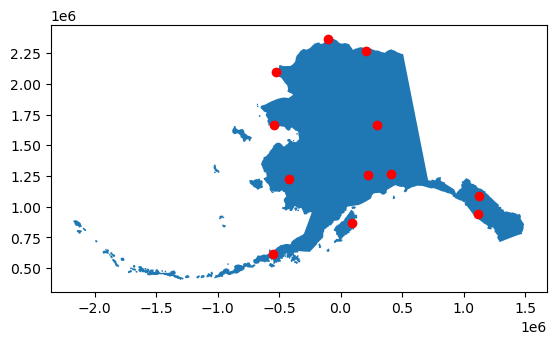

In [32]:
ak_places = gpd.clip(places,alaska)

fig, ax=plt.subplots()

alaska.plot(ax=ax)
ak_places.plot(ax=ax, color='red')
plt.show()

In [33]:
print('CRS:', roads.crs)
print(len(roads))
roads.head()
roads

CRS: EPSG:4326
56600


,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
0,8,Road,Secondary Highway,CAN,None,"Version 1.5: Changed alignment, a few adds in ...",None,None,None,None,0,3,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,314705,North America,0,None,7.1,9.6,"LINESTRING (-133.32533 62.21571, -133.31664 62..."
1,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",83,None,None,None,0,164,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,108105,North America,0,Federal,7.0,8.6,"LINESTRING (-100.50543 42.80753, -100.53495 42..."
2,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",840,None,None,None,0,98,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,U/C,7.0,9.5,"LINESTRING (-87.27432 36.02439, -87.22916 35.9..."
3,8,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",151,None,None,None,0,17,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,Federal,7.1,9.6,"LINESTRING (-87.72757 44.15165, -87.57301 44.1..."
4,6,Road,Major Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",GSP,None,None,None,0,33,1,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,311305,North America,1,State,6.0,8.5,"MULTILINESTRING ((-74.75920 39.14301, -74.6735..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56595,4,Road,Secondary Highway,None,None,New in version 2.0.0,None,None,None,None,0,94,0,global_basic,SH6,None,None,None,None,0,0,0,71863,37478,None,0,Oceania,0,Federal,4.0,7.0,"LINESTRING (168.44462 -45.72081, 168.44570 -45..."
56596,4,Road,Secondary Highway,None,None,New in version 2.0.0,None,None,None,None,0,94,0,global_basic,SH6,None,None,None,None,0,0,0,71863,37478,None,0,Oceania,0,Federal,4.0,7.0,"LINESTRING (168.48463 -45.60669, 168.46426 -45..."
56597,8,Road,Secondary Highway,None,None,New in version 2.0.0,None,None,None,None,0,123,0,global_basic,SH94,None,None,None,None,0,0,0,71864,37479,None,0,Oceania,0,Federal,7.1,9.6,"LINESTRING (168.23276 -45.67076, 168.25352 -45..."
56598,8,Road,Secondary Highway,None,None,New in version 2.0.0,None,None,None,None,0,123,0,global_basic,SH94,None,None,None,None,0,0,0,71864,37479,None,0,Oceania,0,Federal,7.1,9.6,"LINESTRING (167.89803 -45.16523, 167.86984 -45..."


<Axes: >

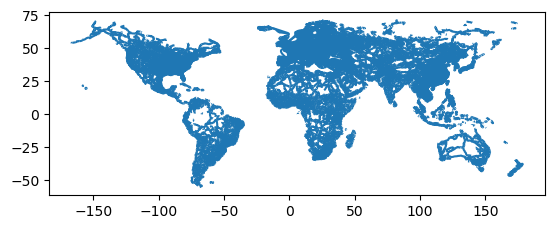

In [34]:
roads.plot()

In [37]:
# What is a road in this dataset? 
roads['type'].value_counts()

type
Unknown              25766
Road                 11531
Major Highway         9752
Secondary Highway     9025
Ferry Route            309
Beltway                168
Track                   39
Bypass                   5
Ferry, seasonal          5
Name: count, dtype: int64

<Axes: >

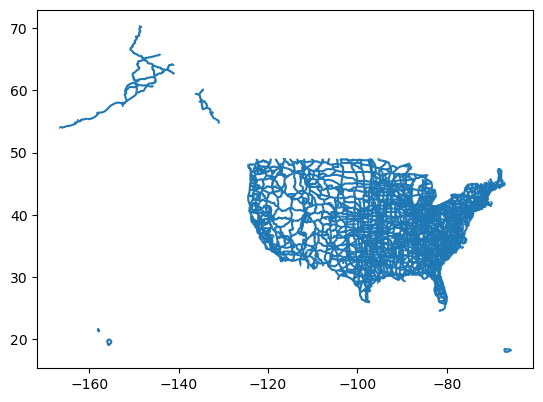

In [40]:
usa_roads=roads[roads['sov_a3']=='USA']
usa_roads.plot()

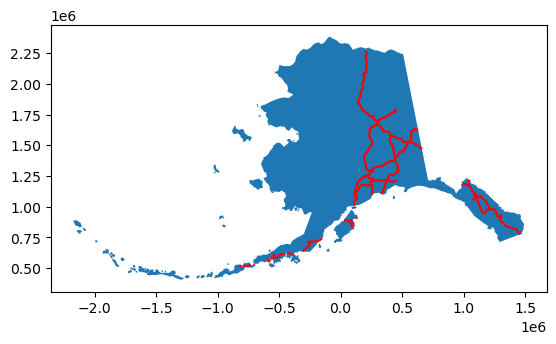

In [39]:
 # Clip usa_roads to alaska geometry
ak_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska)


fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_roads.plot(ax=ax, color='red')
plt.show()

The clipping is excluding roads that could be found over water. Be cautiuse of silent data dropping. 

In [41]:
# Take a look at the values that define the bounding box 
alaska.total_bounds

array([-2175729.73162241,   404545.10791528,  1493082.30904445,
        2383808.43520815])

In [ ]:
# gpd.clip() accepts these four values directly as the mask, so we can clip the roads to Alaska’s bounding box in one step:
ak_complete_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska.total_bounds)


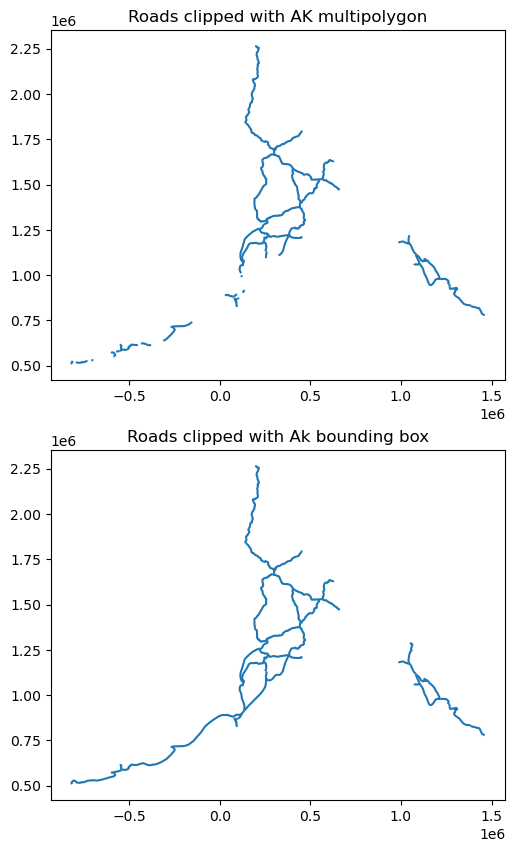

In [46]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,10))
ak_roads.plot(ax=ax1)
ax1.set_title('Roads clipped with AK multipolygon')

ak_complete_roads.plot(ax=ax2)
ax2.set_title("Roads clipped with Ak bounding box")

plt.show()

## Measuring length

Geodataframes have a `length` attribute that calculates the length of each line in the geometry, **in the units of the cRS**

Let's try it on one road of Alaska: 

In [ ]:

# Reminder: usa_roads is is in EPSG:4326
usa_roads

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
1,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",83,None,None,None,0,164,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,108105,North America,0,Federal,7.0,8.6,"LINESTRING (-100.50543 42.80753, -100.53495 42..."
2,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",840,None,None,None,0,98,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,U/C,7.0,9.5,"LINESTRING (-87.27432 36.02439, -87.22916 35.9..."
3,8,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",151,None,None,None,0,17,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,Federal,7.1,9.6,"LINESTRING (-87.72757 44.15165, -87.57301 44.1..."
4,6,Road,Major Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",GSP,None,None,None,0,33,1,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,311305,North America,1,State,6.0,8.5,"MULTILINESTRING ((-74.75920 39.14301, -74.6735..."
6,8,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",85,None,None,None,0,138,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,81005,North America,0,Federal,7.1,9.0,"LINESTRING (-104.45097 42.75717, -104.43881 42..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53799,7,Road,Secondary Highway,USA,None,New in version 2.0.0,45,None,None,None,0,8,0,north_america_extra,None,None,None,None,None,0,0,0,0,5160,US,19864,North America,0,Federal,7.0,9.5,"LINESTRING (-89.20560 46.16094, -89.17869 46.1..."
53800,7,Road,Secondary Highway,USA,None,New in version 2.0.0,18,None,None,None,0,16,0,north_america_extra,None,None,None,None,None,0,0,0,0,5161,US,16480,North America,0,Federal,7.0,8.0,"LINESTRING (-104.19350 43.36071, -104.13071 43..."
53801,7,Road,Secondary Highway,USA,None,New in version 2.0.0,40,None,None,None,0,83,0,north_america_extra,None,None,None,None,None,0,0,0,0,5162,US,6656,North America,0,Federal,7.0,8.0,"LINESTRING (-102.77918 38.76342, -102.75526 38..."
53802,7,Road,Secondary Highway,USA,None,New in version 2.0.0,62,None,None,None,0,20,0,north_america_extra,None,None,None,None,None,0,0,0,0,5163,US,29946,North America,0,Federal,7.0,9.5,"LINESTRING (-100.18078 34.66698, -100.12995 34..."


In [48]:
usa_roads.loc[[1138]].length

/tmp/ipykernel_432883/3731596667.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  usa_roads.loc[[1138]].length


1138    4.051932
dtype: float64

In [ ]:
# Reproject to a projected CRS whose units are meters, EPSG:3338 CRS for Alaska and measure in kilometers
usa_roads.loc[[1138]].to_crs('epsg:3339').length/1000

1138    287.457882
dtype: float64

## How does the clipping affect the data?

In [ ]:
print('Number of roads(polygon clip):', len(ak_roads))
print('Number of roads (bbox clip):', len(ak_complete_roads))
# Did not create nay new roads.

Number of roads(polygon clip): 56
Number of roads (bbox clip): 56


In [ ]:
print('Total length in km(polygon clip):', round(ak_roads.length.sum()/1000))
print('Total length in km(polygon clip):', round(ak_complete_roads.length.sum()/1000))
# Kilometers where lost in clipping ~1000

Total length in km(polygon clip): 6069
Total length in km(polygon clip): 7111


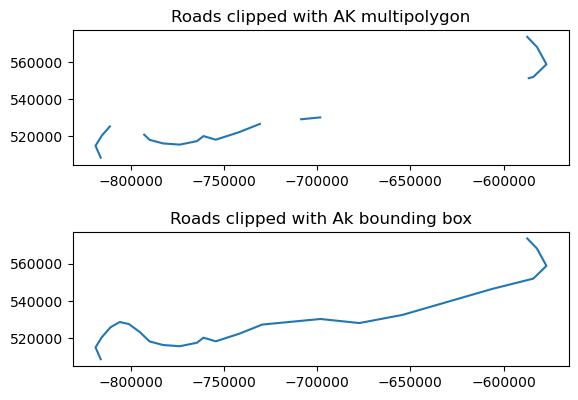

In [58]:
fig, (ax1, ax2) = plt.subplots(2, 1)

ak_roads.loc[[1138]].plot(ax=ax1)
ax1.set_title('Roads clipped with AK multipolygon')

ak_complete_roads.loc[[1138]].plot(ax=ax2)
ax2.set_title("Roads clipped with Ak bounding box")

plt.show()

In [ ]:
print('length of 1138 km(polygon clip):', round(ak_roads.loc[[1138]].length/1000))
print('Total length in km(polygon clip):', round(ak_complete_roads.loc[[1138]].length/1000))

length of 1138 km(polygon clip): 1138    132.0
dtype: float64
Total length in km(polygon clip): 1138    287.0
dtype: float64


In [61]:
ak_roads.loc[[1138]]

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
1138,7,Ferry,Ferry Route,USA,None,New in version 2.0.0,None,None,None,None,0,435,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,4305,North America,0,Ferry,7.0,9.5,"MULTILINESTRING ((-587641.011 573877.088, -582..."


In [62]:
ak_complete_roads.loc[[1138]]

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
1138,7,Ferry,Ferry Route,USA,None,New in version 2.0.0,None,None,None,None,0,435,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,4305,North America,0,Ferry,7.0,9.5,"LINESTRING (-587641.011 573877.088, -582019.27..."


Ensure to be aware of how your GeoData changes as you work with the data. Notice that the length did not change, unsure of how that column was measure. 

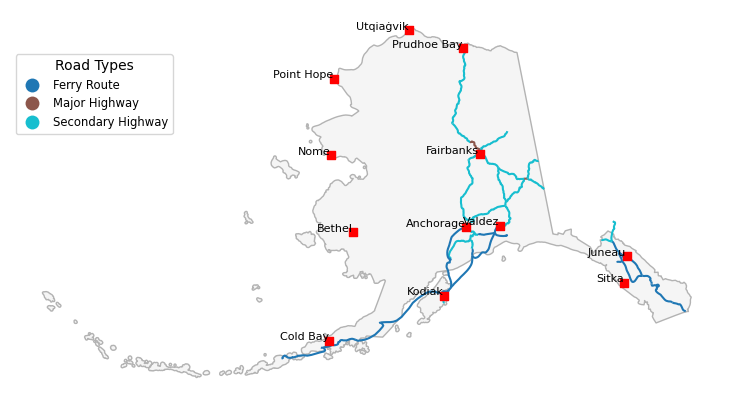

In [72]:
fig, ax=plt.subplots(figsize = (11, 5))
ax.axis('off')

alaska.plot(ax=ax, color='whitesmoke', edgecolor= '0.7')

ak_complete_roads.plot(ax=ax, 
                       zorder=1,  # Specify layer plotting order
                       column='type', 
                       legend=True,
                       legend_kwds={'title': "Road Types", 
                                    'loc': 'upper left',
                                    'bbox_to_anchor':(0,0.9),
                                    'fontsize':'small'}
                                    )

ak_places.plot(ax=ax, 
               zorder=2,  # Specify layer plotting order
               color='red', 
               marker='s'  # Square marker
               )

# Add city names as text annotations 
for x, y, name in zip(ak_places.geometry.x, ak_places.geometry.y, ak_places['name']): 
    ax.text(x-3000,y+2000,name, fontsize=8, ha='right')

plt.show()

Thought excersise: 
1. Seperate overlapping labels 
2. the right side has some roads out of the bounding box: how can we modify to get rid of it? 